# Paper figures (v2)

Figures from the **v2 rerun** (independent test-set phases, per-draw on-the-fly noise `_noisefly`, P_gm against the "1" operator, widened noise priors `_biasnoisenestv2`). Made as v2 outputs finish; see `notes/v2_rerun_tracker.md` for status.

Plotting logic lives in `code/plotter_figs.py`; this notebook points it at the v2 trees (`env_v2.sh` paths) and v2 tags in the setup cell. Figures save to `figures/2026-11-15_paper_figures_v2` (+ `figures/paper_figures_v2_latest`), so the v1 `paper_figures_latest` is untouched.


In [1]:
import os
import sys
from pathlib import Path

# v2 trees (code_auxiliary/env_v2.sh) — must be set before importing paths/data_loader
os.environ["MUCHISIMOCKS_DATA"] = "/scratch/kstoreyf/muchisimocks/data_v2"
os.environ["MUCHISIMOCKS_RESULTS"] = "/scratch/kstoreyf/muchisimocks/results_v2"

REPO_ROOT = Path.cwd()
if REPO_ROOT.name == "notebooks":
    REPO_ROOT = REPO_ROOT.parent
sys.path.insert(0, str(REPO_ROOT / "code"))

import plotter_figs as pf

%load_ext autoreload
%autoreload 2

# v2 training set
pf.TAG_BIASPARAMS_TRAIN = "_biasnoisenestv2_p9_n320000"
pf.TAG_NOISE_TRAIN = "_noisefly"
print("data:", pf.paths.DIR_DATA, "| results:", pf.paths.DIR_RESULTS)
print("train:", pf.TAG_PARAMS_TRAIN, pf.TAG_BIASPARAMS_TRAIN, pf.TAG_NOISE_TRAIN)

pf.configure_figures(
    save=True,
    fig_dir=REPO_ROOT / "figures" / "2026-11-15_paper_figures_v2",
    fig_dir_latest=REPO_ROOT / "figures" / "paper_figures_v2_latest",
    ext="pdf",
)


2026-11-16 06:48:22.224395: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-11-16 06:48:22.261834: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-11-16 06:48:22.348710: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-11-16 06:48:22.348759: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-11-16 06:48:22.361281: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to

data: /scratch/kstoreyf/muchisimocks/data_v2 | results: /scratch/kstoreyf/muchisimocks/results_v2
train: _p5_n10000 _biasnoisenestv2_p9_n320000 _noisefly
SAVE_FIGURES: True
FIG_DIR: /home/kstoreyf/muchisimocks/figures/2026-11-15_paper_figures_v2
FIG_DIR_LATEST: /home/kstoreyf/muchisimocks/figures/paper_figures_v2_latest
OVERWRITE_FIGURES: True
FIG_EXT: pdf


{'SAVE_FIGURES': True,
 'FIG_DIR': PosixPath('/home/kstoreyf/muchisimocks/figures/2026-11-15_paper_figures_v2'),
 'FIG_DIR_LATEST': PosixPath('/home/kstoreyf/muchisimocks/figures/paper_figures_v2_latest'),
 'OVERWRITE_FIGURES': True,
 'FIG_EXT': 'pdf'}

## 2. Statistics: training-set ranges

Median with 16–84% and 1–99% bands over 100 random training cosmologies × 32 bias/noise draws (v2 training set), with the SHAMe OOD mocks at three $\bar n$ overplotted (dashed grey).

- **SHAMe lines are unchanged from v1:** SHAMe P, P_gm and B were computed from the SHAMe catalogs and N-body matter field (`data/data_shame/data_nbar*/`, March 2026), and their binning matches v2 training (32 P/P_gm bins, 203 triangles). The v2 P_gm fix changed the *muchisimocks* side to agree with SHAMe's matter field, so the P_gm training band is the part that moved.
- **Bispectrum is partial** while the training bispec job (7975566) runs: the panel uses only cosmologies with all 32 bias files done, and the figure isn't cached until every statistic is complete. Rerun this cell once bispec finishes.


Training stats incomplete (complete cosmologies: {'bispec': 2673} of 10000); not caching
Loaded pk with shape (32,)
Loaded pgm with shape (32,)
Loaded bispec with shape (203,)
Loaded pk with shape (32,)
Loaded pgm with shape (32,)
Loaded bispec with shape (203,)
Loaded pk with shape (32,)
Loaded pgm with shape (32,)
Loaded bispec with shape (203,)
dir_statistics: /scratch/kstoreyf/muchisimocks/data_v2/pks_mlib/pks_p5_n10000_biasnoisenestv2_p9_n320000_noisefly
Loading muchisimocks data from /scratch/kstoreyf/muchisimocks/data_v2/pks_mlib/pks_p5_n10000_biasnoisenestv2_p9_n320000_noisefly
Found 10000 diff cosmo pks in /scratch/kstoreyf/muchisimocks/data_v2/pks_mlib/pks_p5_n10000_biasnoisenestv2_p9_n320000_noisefly
Filtered to 100 cosmologies (cosmo_indices)
dir_statistics: /scratch/kstoreyf/muchisimocks/data_v2/pgms_mlib/pgms_p5_n10000_biasnoisenestv2_p9_n320000_noisefly
Loading muchisimocks data from /scratch/kstoreyf/muchisimocks/data_v2/pgms_mlib/pgms_p5_n10000_biasnoisenestv2_p9_n3200

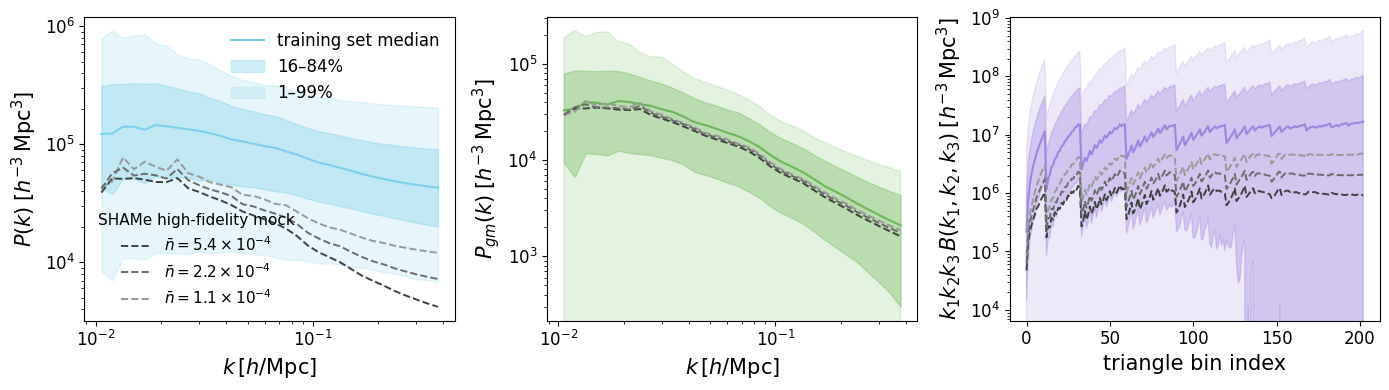

In [2]:
pf.plot_fig2_statistics_ranges()


## Still waiting on

- **Fig 3 (cosmic variance), Fig 6 (SHAMe contours), Fig 7–9 (n̄ / scale dependence):** need v2 trained models (noise-in-θ A/B runs 7975888 first, then fiducial combos after the θ decision; bispec combos after bispec finishes) and the `_shamev2_p0_n1000` test set (datagen 7973621).
- **Fig 4/5 (coverage):** need `_coveragev2_p5_n1000` stats (datagen 7973620) + models.
- **Fig 10/11 (convergence):** need the full v2 training grid.
